In [8]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
import torch
from torch.utils.data import DataLoader

# # Import podpůrných funkcí z utils3.py
# current_dir = Path.cwd()
# if str(current_dir) not in sys.path:
#     sys.path.insert(0, str(current_dir))

from CNN import CustomCNN, get_pretrained_resnet
from SiameseCNN import evaluate_siamese_distances, SiameseNetwork, train_siamese_network, SiameseDataset, generate_siamese_pairs
from plotData import *
from utils3 import prepare_classification_dataset, set_seed

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Device: cpu


In [9]:
cells_dir = Path.cwd().resolve().parent / "Data" / "cells"
masks_dir = Path.cwd().resolve().parent / "Data" / "masks_pts"
print(f"Cells: {cells_dir}")
print(f"Masks: {masks_dir}")

train_data, val_data = prepare_classification_dataset(cells_dir, masks_dir, val_ratio=0.2, img_size=256)
print(f"Training samples: {len(train_data)}")
print(f"Validation samples: {len(val_data)}")

Cells: C:\Users\galem\Documents\FIT-CTU\ANI-PIV\Data\cells
Masks: C:\Users\galem\Documents\FIT-CTU\ANI-PIV\Data\masks_pts
Training samples: 251
Validation samples: 63


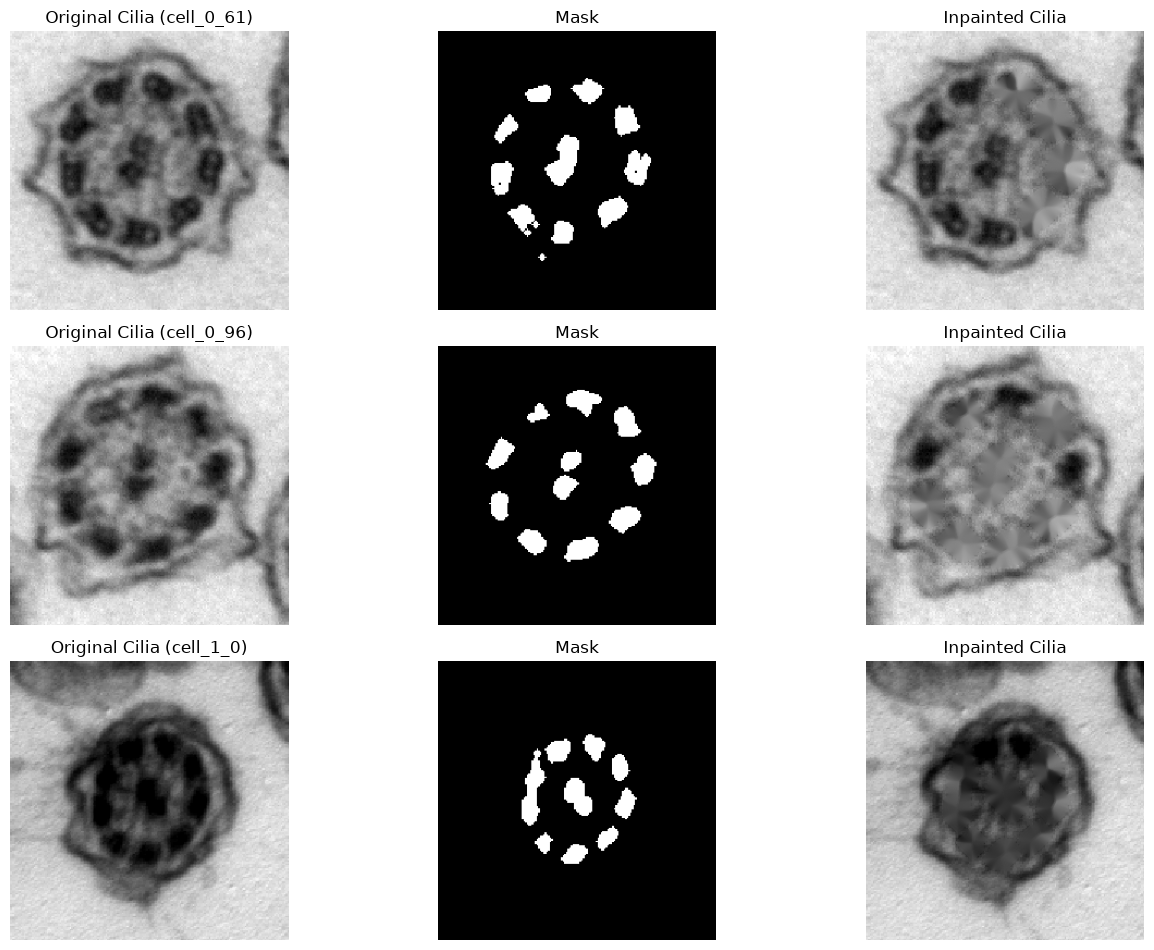

In [10]:
plot_dataset_samples(val_data, num_examples=3, save_path="/IMGS3/dataset_samples.png")

In [11]:
batch_size = 32
train_dataset = CiliaClassificationDataset(train_data, img_size=256, augment=True)
val_dataset = CiliaClassificationDataset(val_data, img_size=256, augment=False)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [12]:
custom_model = CustomCNN(num_classes=2, dropout=0.3).to(device)

hist_custom = train_classifier(
    custom_model,
    train_loader,
    val_loader,
    num_epochs=5,
    lr=1e-3,
    device=device
)

Epoch  | Train Loss  | Train Acc  | Val Loss   | Val Acc   
--------------------------------------------------------
1      | 0.5670      | 0.7251     | 0.5514     | 0.7857    


KeyboardInterrupt: 

In [ ]:
# 2. ResNet18 – Freeze feature extractor
resnet_frozen = get_pretrained_resnet(
    num_classes=2, fine_tune=False).to(device)

hist_frozen = train_classifier(
    resnet_frozen, train_loader, val_loader, num_epochs=5, lr=1e-3, device=device)

# 3. ResNet18 – Fine-tune entire model
resnet_finetune = get_pretrained_resnet(num_classes=2, fine_tune=True).to(device)

hist_finetune = train_classifier(
    resnet_finetune, train_loader, val_loader, num_epochs=5, lr=1e-4, device=device)

Epoch  | Train Loss  | Train Acc  | Val Loss   | Val Acc   
--------------------------------------------------------


RuntimeError: Given groups=1, weight of size [64, 3, 7, 7], expected input[64, 1, 256, 256] to have 3 channels, but got 1 channels instead

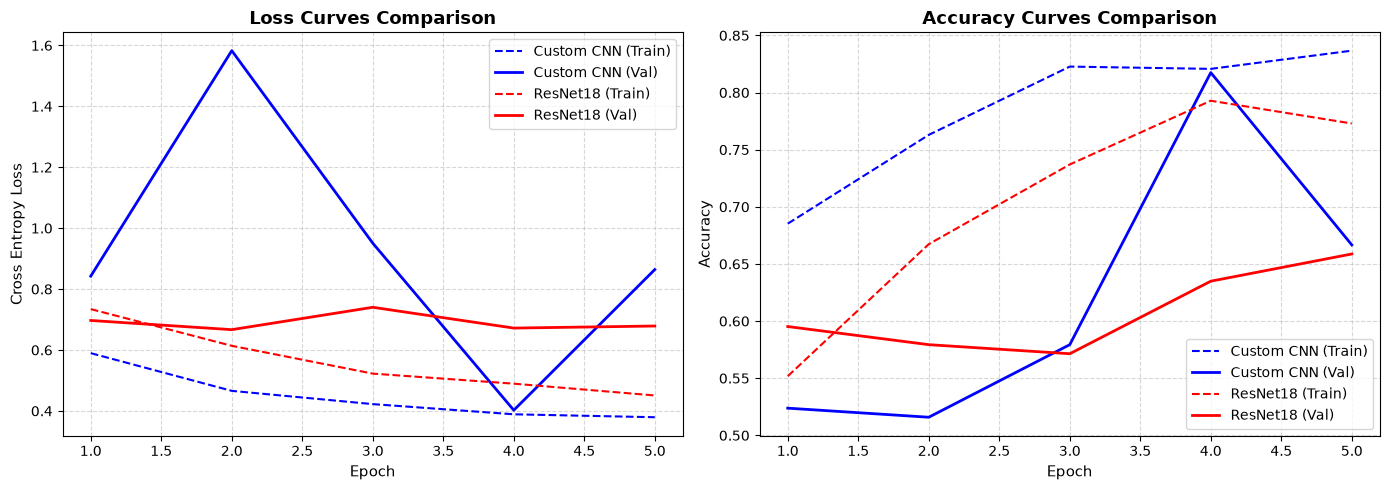

In [ ]:
plot_training_comparison(hist_custom, hist_frozen,
                         save_path="/IMGS3/models_comparisonFreeze.png")

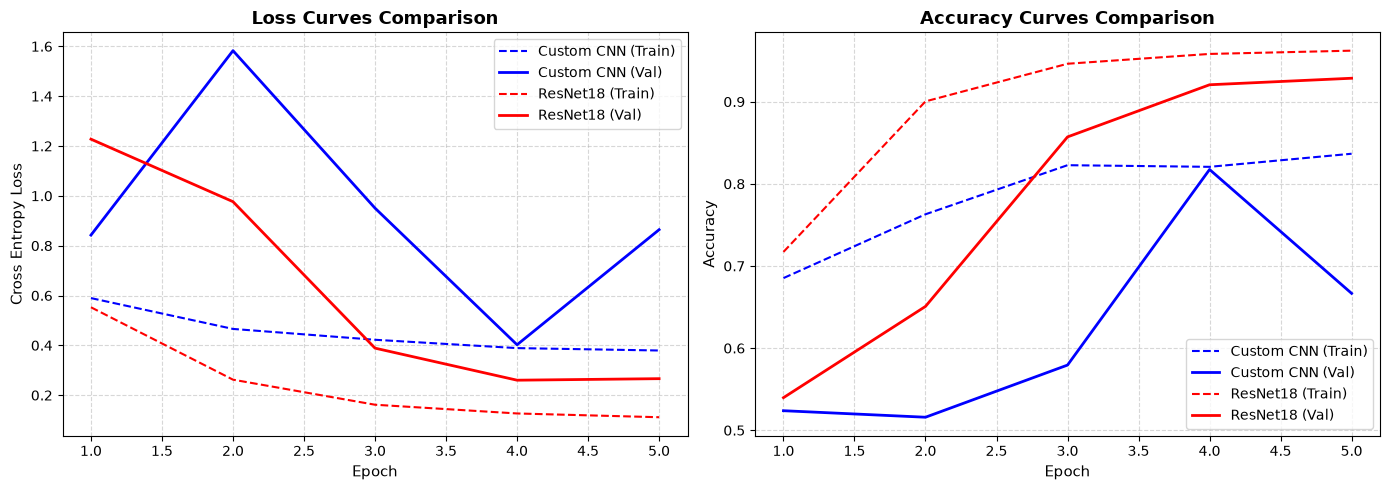

In [ ]:
plot_training_comparison(hist_custom, hist_finetune,
                         save_path="/IMGS3/models_comparisonFine.png")

=== CustomCNN ===
Accuracy:  0.6667
Precision: 0.9565
Recall:    0.3492
F1-Score:  0.5116

=== RESNET18 ===
Accuracy:  0.9286
Precision: 1.0000
Recall:    0.8571
F1-Score:  0.9231


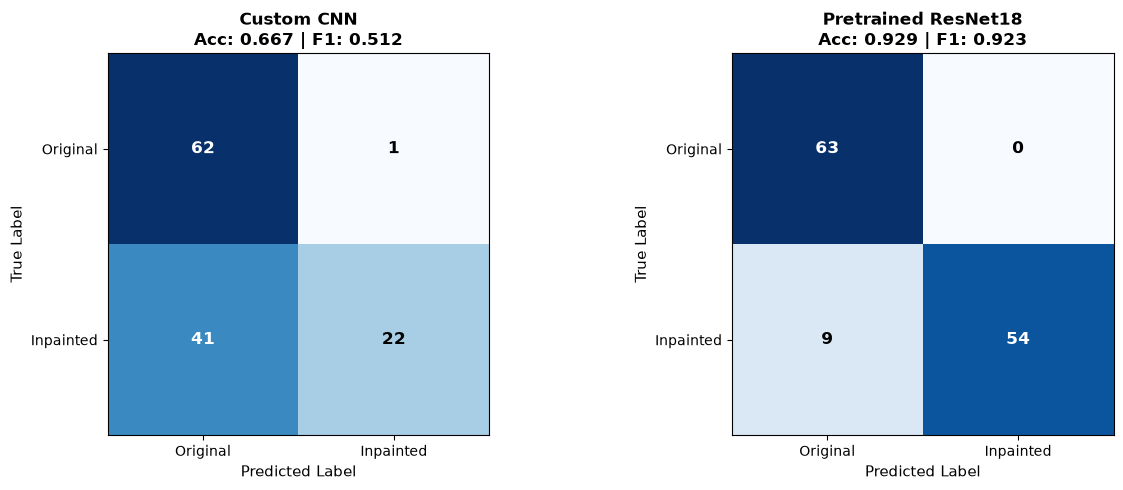

In [ ]:
metrics_custom = compute_classification_metrics(custom_model, val_loader, device=device)
metrics_resnet = compute_classification_metrics(
    resnet_finetune, val_loader, device=device)

print("=== CustomCNN ===")
print(f"Accuracy:  {metrics_custom['accuracy']:.4f}")
print(f"Precision: {metrics_custom['precision']:.4f}")
print(f"Recall:    {metrics_custom['recall']:.4f}")
print(f"F1-Score:  {metrics_custom['f1']:.4f}")

print("\n=== RESNET18 ===")
print(f"Accuracy:  {metrics_resnet['accuracy']:.4f}")
print(f"Precision: {metrics_resnet['precision']:.4f}")
print(f"Recall:    {metrics_resnet['recall']:.4f}")
print(f"F1-Score:  {metrics_resnet['f1']:.4f}")

plot_confusion_matrices(metrics_custom, metrics_resnet,
                        save_path="/IMGS3/confusion_matrices.png")

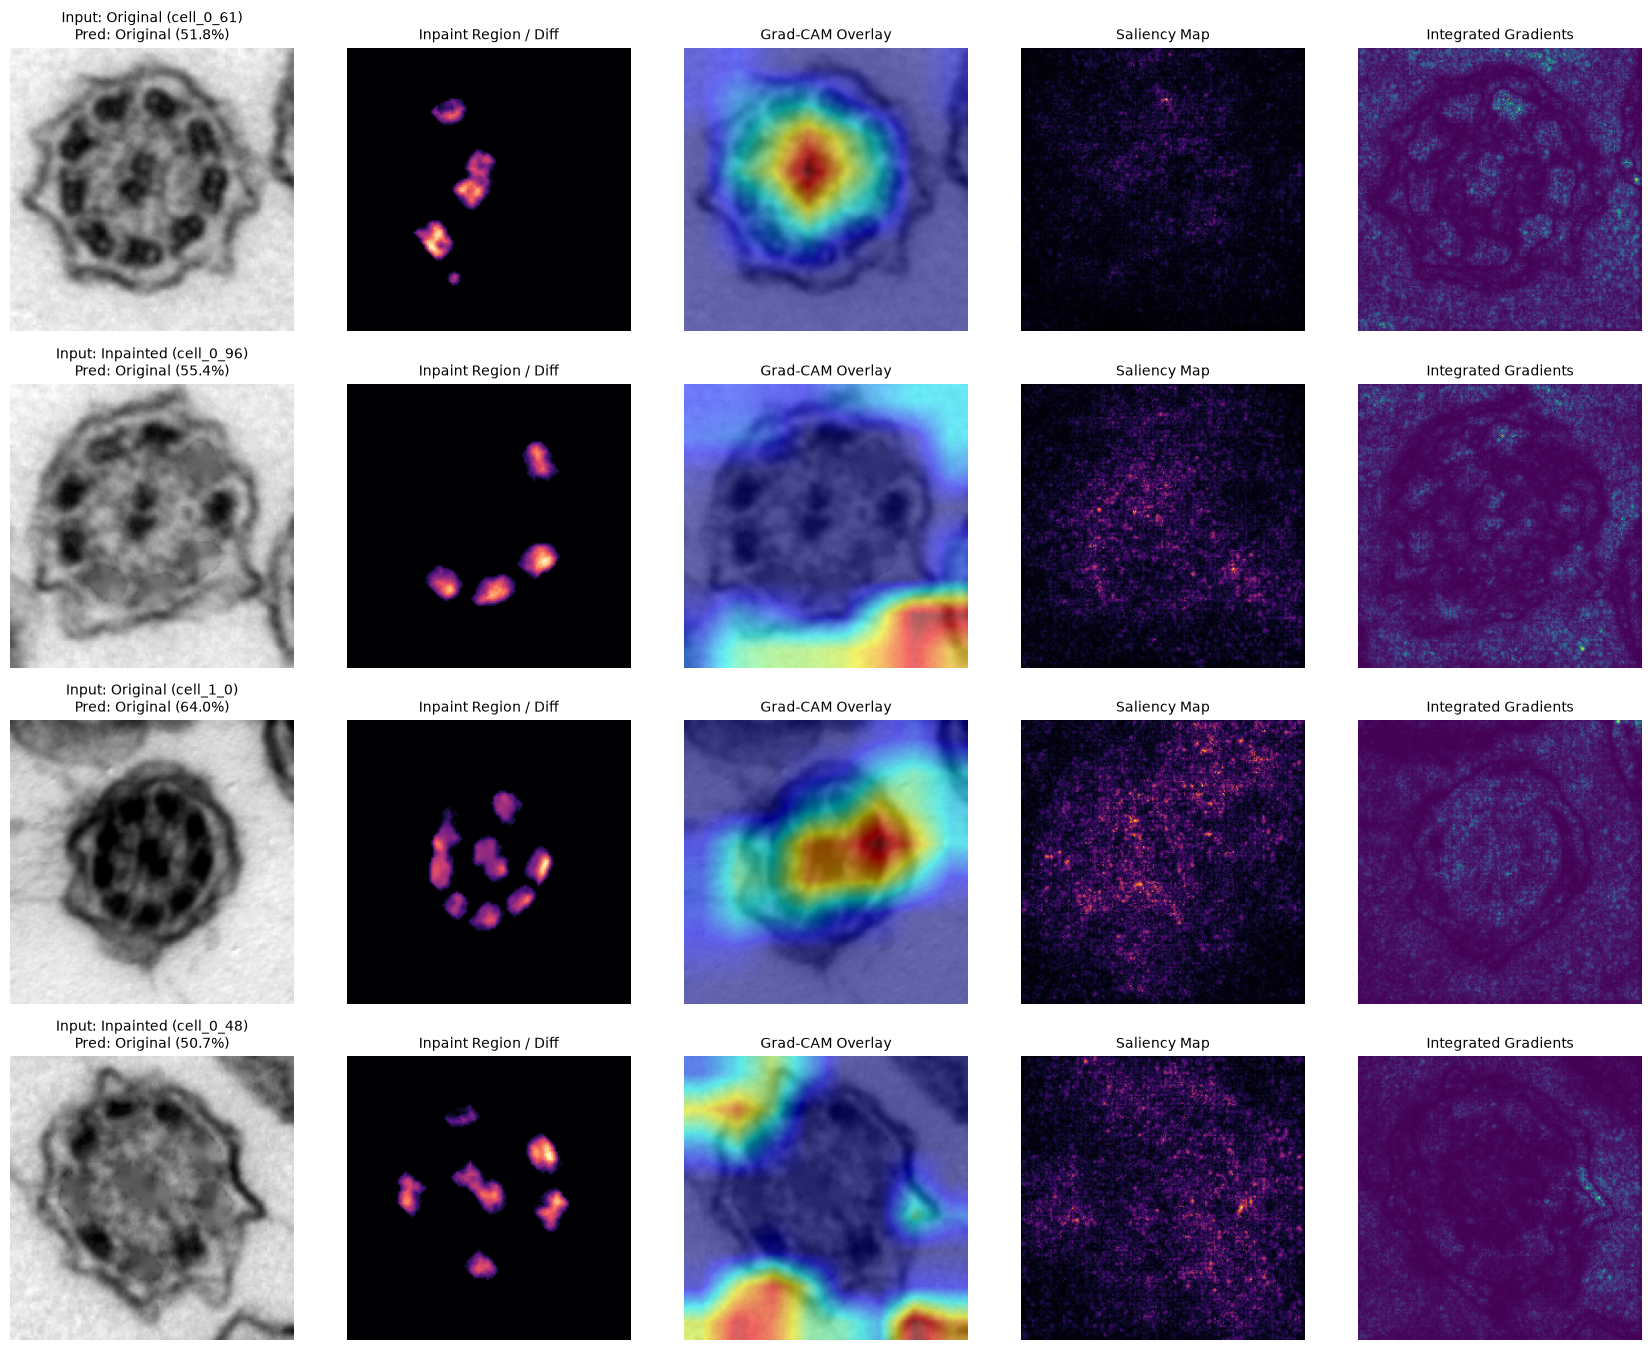

In [ ]:
selected_samples = [val_data[i] for i in [0, 1, 2, 3]]

plot_xai_samples(
    resnet_frozen,
    selected_samples,
    target_layer=resnet_frozen.layer4[-1].conv2,
    img_size=256,
    device=device,
    save_path="/IMGS3/xai_samples_resnetFreeze.png"
)

In [ ]:
plot_xai_samples(
    resnet_finetune,
    selected_samples,
    target_layer=resnet_finetune.layer4[-1].conv2,
    img_size=256,
    device=device,
    save_path="/IMGS3/xai_samples_resnetFine.png"
)

In [ ]:
plot_xai_samples(
    custom_model,
    selected_samples,
    target_layer=custom_model.extract_features[-1].block[0],
    img_size=256,
    device=device,
    save_path="/IMGS3/xai_samples_custom.png"
)

SyntaxError: expected argument value expression (2077604666.py, line 7)

In [ ]:
train_pairs = generate_siamese_pairs(train_data, num_pairs=1000)
val_pairs = generate_siamese_pairs(val_data, num_pairs=300)

siamese_train_ds = SiameseDataset(train_pairs, img_size=256, augment=True)
siamese_val_ds = SiameseDataset(val_pairs, img_size=256, augment=False)

siamese_train_loader = DataLoader(siamese_train_ds, batch_size=32, shuffle=True)
siamese_val_loader = DataLoader(siamese_val_ds, batch_size=32, shuffle=False)

print(f"Train: {len(train_pairs)} (50% positive, 50% negative)")
print(f"Validation: {len(val_pairs)} (50% positive, 50% negative)")

Train: 1000 (50% positive, 50% negative)
Validation: 300 (50% positive, 50% negative)


In [ ]:
siamese_model = SiameseNetwork(in_channels=3, embedding_dim=64).to(device)

hist_siamese = train_siamese_network(
    siamese_model,
    siamese_train_loader,
    siamese_val_loader,
    num_epochs=5,
    lr=1e-3,
    margin=1.0,
    device=device
)

Epoch  | Train Loss   | Val Loss     | Val Acc (tau=0.5)
-------------------------------------------------------
1      | 0.1394       | 0.1444       | 0.4800         
2      | 0.1378       | 0.1334       | 0.5333         
3      | 0.1371       | 0.1399       | 0.5233         
4      | 0.1367       | 0.1311       | 0.5167         
5      | 0.1357       | 0.1269       | 0.5400         


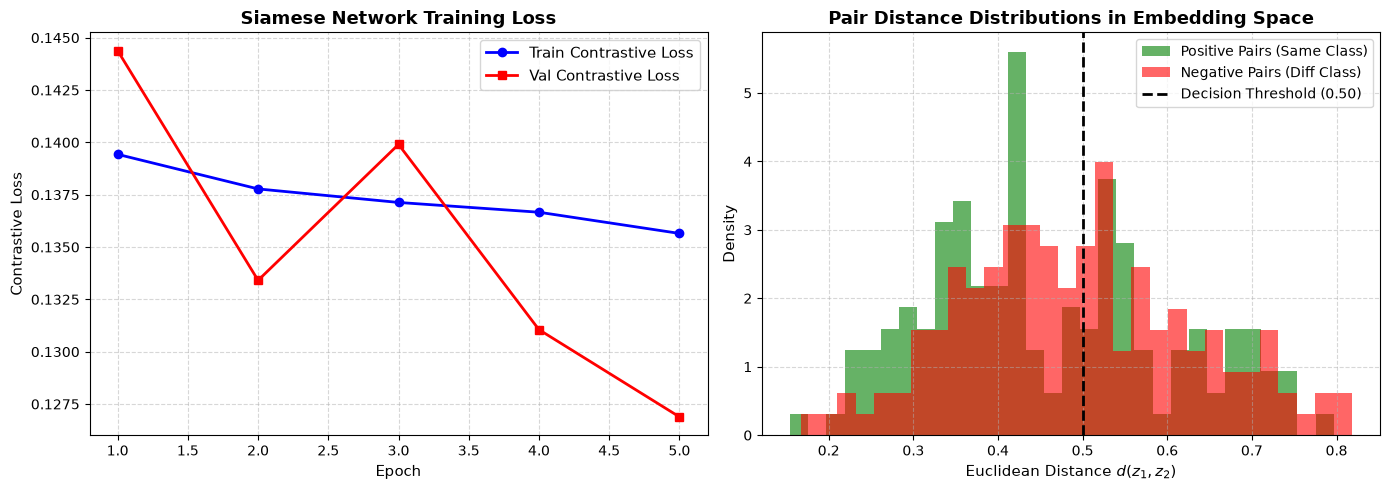

In [ ]:
pos_dists, neg_dists = evaluate_siamese_distances(siamese_model, siamese_val_loader, device=device)
plot_siamese_results(hist_siamese, pos_dists, neg_dists,
                     threshold=0.5, save_path="/IMGS3/siamese_results.png")

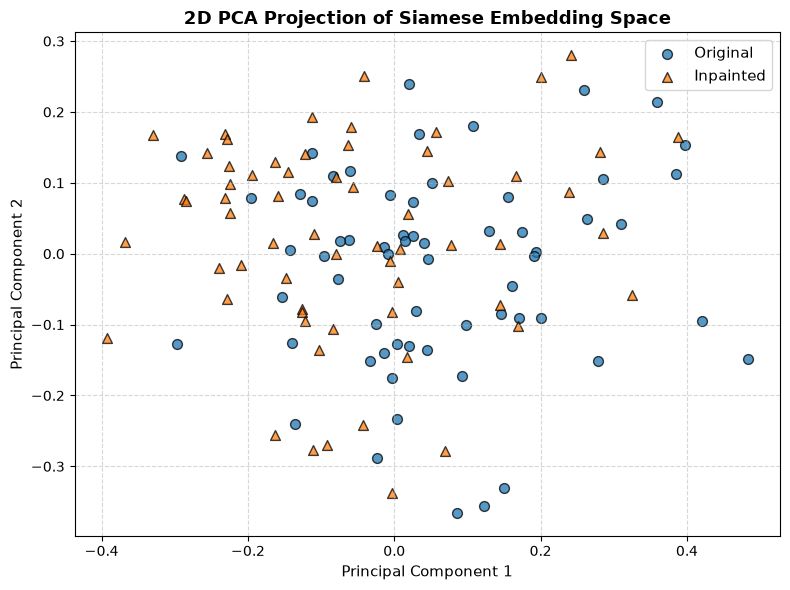

In [ ]:
val_embeddings, val_labels = extract_embeddings(siamese_model, val_data, img_size=256, device=device)
plot_embedding_space_pca(val_embeddings, val_labels,
                         save_path="/IMGS3/siamese_embedding_pca.png")

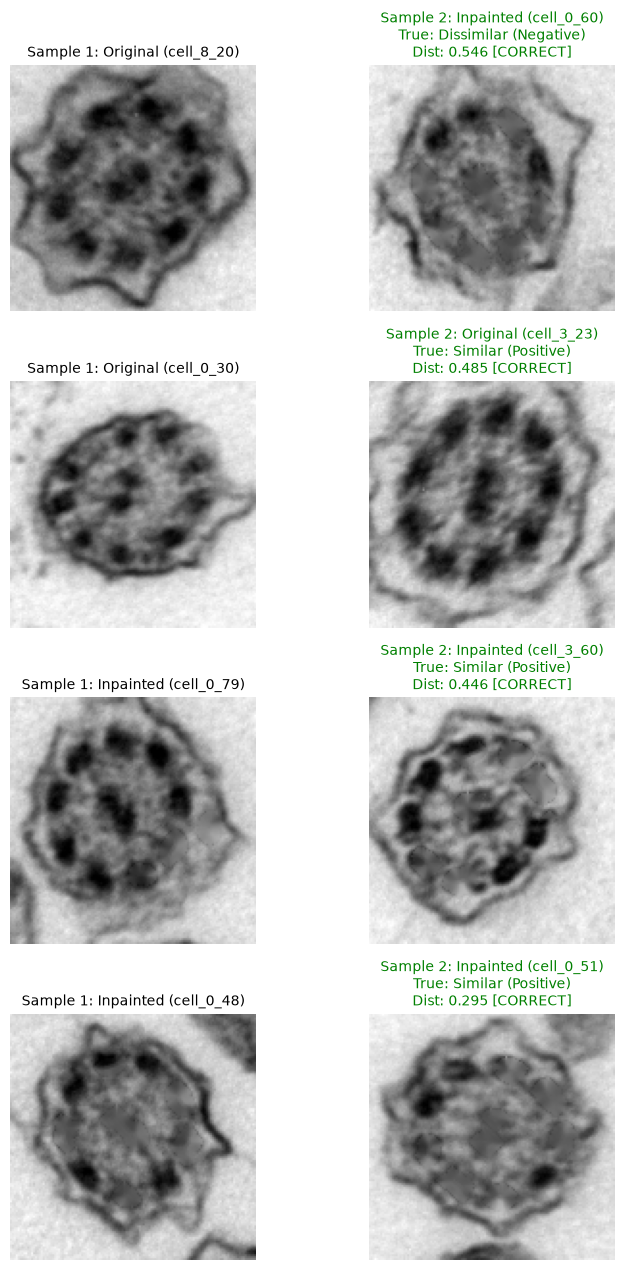

In [ ]:
plot_siamese_pair_examples(
    siamese_model,
    val_pairs,
    num_examples=4,
    img_size=128,
    threshold=0.5,
    device=device,
    save_path="/IMGS3/siamese_pairs_examples.png"
)